In [8]:
import pandas as pd
import numpy as np

In [9]:
major_supermarkets = ['coles', 'woolworths', 'foodworks', 'iga', 'aldi', 'ritchies', 'safeway']

lines = pd.read_csv('../data/landing/supermarket_raw_data.csv', header=None)

lst = []
prev = None

for i in range(len(lines.values)):
    swap = False

    line = lines.values[i][0]
    if not swap:
        if i % 2 == 0:
            prev = line
        else:
            pscd = line[-4:]
            town = line[:-5]
            if pscd[0] == '3':
                lst.append([prev, town, int(pscd)])
            else:
                swap = True

    if swap:
        if i % 2 == 1:
            prev = line
        else:
            pscd = line[-4:]
            town = line[:-5]
            if pscd[0] == '3':
                lst.append([prev, town, int(pscd)])
            else:
                swap = False

df = pd.DataFrame(lst, columns=['Supermarket', 'Town', 'Postcode'])
df = df.drop_duplicates().reset_index(drop=True)

df['Major'] = df['Supermarket'].str.contains('|'.join(major_supermarkets))

gb = df.groupby(['Postcode']).agg(
        Total_Supermarkets=('Supermarket', 'count'),
        Major_Supermarkets=('Major', 'sum'),
    )

df

gb.to_csv('../data/curated/supermarket_data.csv')

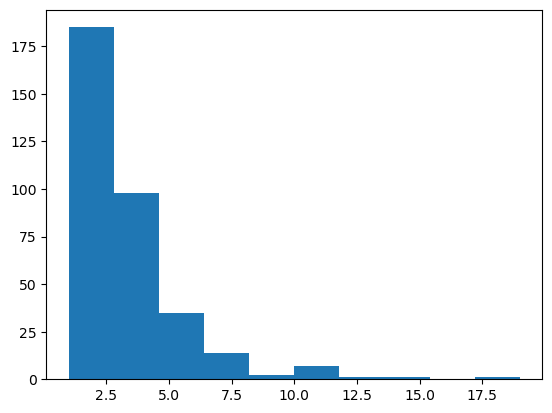

In [10]:
plt.hist(gb['Total_Supermarkets'])
plt.show()

In [11]:
#gb.to_csv('../data/curated/supermarket_data.csv')